# Effect of the number of thresholds on VUS-PR

While the VUS-PR metric is a highly qualitative evaluation metric for time series anomaly detection, it is computationally expensive. One key parameter is the number of  thresholds used for creating a surface. The larger the number of thresholds, the more closely the discretised surface approximates the true surface, but the more resources are necessary. This notebooks analyses the effect of this parameter for the VUS-PR metric. 

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from hydraad import HydraAD, TSBADLoader, VolumeUnderPR_TSBAD
from scripts.run_experiment import initialize_dataloaders

In [2]:
n_repeats = 3
detector = HydraAD("fft")

## Effect on run time

In [3]:
thresholds = [10, 20, 50, 75, 100, 150, 250, 300, 500, 750]

dataset = TSBADLoader(
    path="../data/TSB-AD-U/008_NAB_id_8_Synthetic_tr_1007_1st_2734.csv"
).load()
X_test = dataset.X_test
y_test = dataset.y_test

times = {}
for threshold in thresholds:
    vus_pr = VolumeUnderPR_TSBAD(threshold=threshold)
    times[threshold] = []

    for i in range(n_repeats):
        y_pred = detector.fit(X_test).decision_function(X_test)

        start = time.time()
        vus_pr.compute(y_test, y_pred)
        total_time = time.time() - start

        times[threshold].append(total_time)

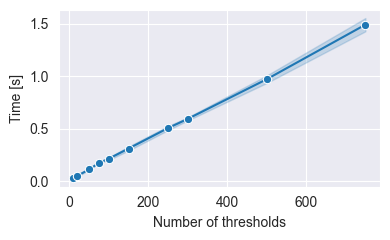

In [27]:
df = pd.DataFrame.from_dict(times, orient="index").transpose()
df_long = df.melt(var_name="Number of thresholds", value_name="Time [s]")
plt.figure(figsize=(4, 2.5))
sns.lineplot(
    data=df_long, x="Number of thresholds", y="Time [s]", errorbar="sd", marker="o"
)
plt.tight_layout()
plt.savefig("figures/fig-vus-pr-time.png", bbox_inches="tight")

In [5]:
sum(times[250]) / n_repeats

0.5069243113199869

In [6]:
%timeit detector.fit(X_test).decision_function(X_test)

20.4 ms ± 2.05 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


## Effect on quantitative evaluation

In [7]:
loaders = []
for loader in initialize_dataloaders("../data", "U", "Eva"):
    length = loader.load().X_test.shape[0]
    if 2_500 <= length <= 5_000:
        loaders.append(loader)

thresholds = [20, 50, 75, 100, 150]

differences = {t: [] for t in thresholds}
for loader in loaders:
    dataset = loader.load()

    for i in range(n_repeats):
        y_pred = detector.fit(X_test).decision_function(dataset.X_test)
        vus_pr = VolumeUnderPR_TSBAD(threshold=250).compute(dataset.y_test, y_pred)

        for threshold in thresholds:
            vus_pr_ = VolumeUnderPR_TSBAD(threshold=threshold).compute(
                dataset.y_test, y_pred
            )
            differences[threshold].append(vus_pr - vus_pr_)

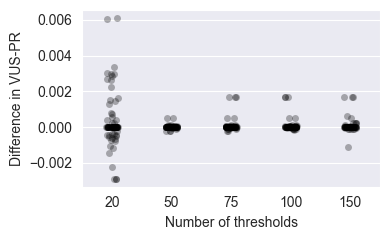

In [28]:
df = pd.DataFrame.from_dict(differences, orient="index").transpose()
df_long = df.melt(var_name="Number of thresholds", value_name="Difference in VUS-PR")
df_long = df_long[df_long["Number of thresholds"] != 10]
plt.figure(figsize=(4, 2.5))
sns.stripplot(
    data=df_long,
    x="Number of thresholds",
    y="Difference in VUS-PR",
    color="black",
    alpha=0.3,
)
plt.tight_layout()
plt.savefig("figures/fig-vus-pr-variation.png", bbox_inches="tight")

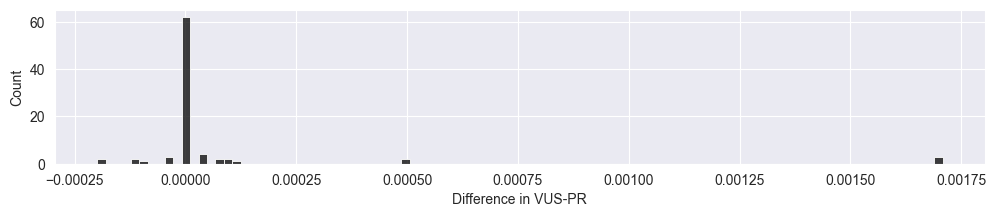

In [25]:
plt.figure(figsize=(12, 2))
sns.histplot(
    data=df_long[df_long["Number of thresholds"] == 75],
    x="Difference in VUS-PR",
    bins=100,
    color="black",
);

## Conclusion

The runtime scales linearly with the number of thresholds. However, lowering the threshold also implies more variability in the obtained scores. The experiments indicated that the number of thresholds can be lowered until 75 with minimal effect on the performance (generally less than 0.005 difference). In addition, by lowering the number of thresholds, the accuracy generally tends to decrease, which implies that we have a more pessimistic evaluation, which avoids promoting bad methods as being good. This effect will be minimized by repeating the experiments several times. 